# LSTM 电影评论情感分析：原版

这个 Notebook 以课程项目中的原始 LSTM 代码为主体，只修复会导致无法完整运行的问题，
并保留一次真实执行结果。原实验中的 Embedding 可训练状态不同、padding 会进入 LSTM、
使用最后一轮模型等设计问题仍然保留，因此它用于展示项目起点，而不是严格对照实验。

> 数据、GloVe 和模型权重不放进 Git 仓库。运行方法见同目录的 `README.md`。


In [1]:
import collections
import glob
import json
import os
import random
import re
import sys
import time
import warnings
from pathlib import Path

import datasets
import matplotlib.pyplot as plt
import nltk
import numpy as np
import torch
import torch.nn as nn
from bs4 import BeautifulSoup
from datasets import Dataset, DatasetDict
from nltk.tokenize import word_tokenize
from sklearn.metrics import auc, roc_curve
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader

warnings.filterwarnings("ignore", category=UserWarning)
datasets.disable_progress_bar()
datasets.disable_caching()

SEED = 42
ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
print("CUDA available:", torch.cuda.is_available())
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 本地已有 NLTK 资源时不联网下载，避免重复下载和网络失败。
for package, resource in (("corpora", "stopwords"), ("tokenizers", "punkt")):
    try:
        nltk.data.find(f"{package}/{resource}")
    except LookupError:
        nltk.download(resource, quiet=True)


device: cuda
CUDA available: True
PyTorch: 2.14.1+cu126
CUDA: 12.6
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 1. 数据准备

原实验从 IMDb `train/pos` 和 `train/neg` 读取 25,000 条评论，然后按
80% / 10% / 10% 划分为训练集、验证集和测试集。


In [3]:
def load_and_split_data(data_path):
    data = []
    labels = []

    for label, label_val in [("pos", 1), ("neg", 0)]:
        dir_path = f"{data_path}/{label}"
        files = glob.glob(f"{dir_path}/*.txt")
        for file in files:
            with open(file, "r", encoding="utf-8") as f:
                data.append(f.read().strip())
            labels.append(label_val)

    dataset = Dataset.from_dict({"text": data, "label": labels})

    # train 80%, validation 10%, test 10%
    train_test_split = dataset.train_test_split(test_size=0.2, seed=42)
    test_val_split = train_test_split["test"].train_test_split(
        test_size=0.5, seed=42
    )

    return DatasetDict(
        {
            "train": train_test_split["train"],
            "validation": test_val_split["train"],
            "test": test_val_split["test"],
        }
    )


def find_data_path(env_name, relative_path):
    env_value = os.getenv(env_name)
    if env_value:
        path = Path(env_value)
        if path.exists():
            return path

    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / relative_path
        if candidate.exists():
            return candidate

    raise FileNotFoundError(
        f"找不到 {relative_path}，请设置环境变量 {env_name} 为实际路径。"
    )


root_dir = find_data_path("IMDB_TRAIN_DIR", "data/aclImdb/train")
dataset = load_and_split_data(root_dir)

print({name: len(split) for name, split in dataset.items()})
print("First label:", dataset["train"][0]["label"])
print("First review characters:", len(dataset["train"][0]["text"]))


{'train': 20000, 'validation': 2500, 'test': 2500}
First label: 0
First review characters: 591


In [4]:
def preprocess_text(text):
    # 清理 HTML 标签，转小写，只保留字母和空白，然后分词并删除 NLTK 停用词。
    # 这个停用词处理会误删 not/nor 等否定词；原版保留这一行为，改进版单独讨论。
    filterwords = nltk.corpus.stopwords.words("english")

    text = BeautifulSoup(text, "html.parser").get_text()
    text = text.lower()
    text = re.sub(r"[^a-z\s]", "", text)
    tokens = word_tokenize(text)
    return [token for token in tokens if token not in filterwords]


In [5]:
dataset = dataset.map(
    lambda example: {"tokens": preprocess_text(example["text"])},
    batched=False,
    num_proc=1,
)

print("First 30 tokens:", dataset["train"][0]["tokens"][:30])
print("Tokenized rows:", len(dataset["train"]), len(dataset["validation"]), len(dataset["test"]))


First 30 tokens: ['waaaaay', 'much', 'frustrating', 'watch', 'waiting', 'whole', 'damn', 'movie', 'end', 'finally', 'get', 'answers', 'ive', 'end', 'nothing', 'huuuge', 'neonsign', 'question', 'mark', 'head', 'havent', 'seen', 'bad', 'acting', 'nonsense', 'movie', 'long', 'long', 'time', 'whats']
Tokenized rows: 20000 2500 2500


## 2. 词表与词向量

只从训练集构建 10,000 词词表，前两个位置固定为 `<pad>` 和 `<unk>`。


In [6]:
def build_vocab(token_list, max_size=10000):
    all_tokens = [token for tokens in token_list for token in tokens]
    counter = collections.Counter(all_tokens)
    most_common = counter.most_common(max_size - 2)
    vocab_tokens = ["<pad>", "<unk>"] + [token for token, _ in most_common]
    stoi = {token: index for index, token in enumerate(vocab_tokens)}
    itos = {index: token for token, index in stoi.items()}
    return stoi, itos, len(stoi)


stoi, itos, vocab_size = build_vocab(dataset["train"]["tokens"])
print("Vocabulary size:", vocab_size)
print("First five tokens:", list(stoi.items())[:5])


Vocabulary size: 10000
First five tokens: [('<pad>', 0), ('<unk>', 1), ('movie', 2), ('film', 3), ('one', 4)]


In [7]:
def load_glove_embeddings(glove_file, stoi, embedding_dim=300, seed=42):
    embedding = np.random.normal(
        size=(len(stoi), embedding_dim)
    ).astype(np.float32)
    found = 0
    with open(glove_file, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split()
            word = parts[0]
            if word in stoi:
                embedding[stoi[word]] = np.asarray(parts[1:], dtype=np.float32)
                found += 1
    return torch.tensor(embedding), found


glove_file = find_data_path(
    "GLOVE_PATH", "data/glove/glove.6B.300d.txt"
)
# 此处保持原版：随机向量表在模型训练开始前用 NumPy 生成。
np.random.seed(SEED)
pretrained_embeddings, glove_found = load_glove_embeddings(
    glove_file, stoi, embedding_dim=300, seed=SEED
)
print("Embedding shape:", tuple(pretrained_embeddings.shape))
print(f"GloVe coverage: {glove_found}/{vocab_size} = {glove_found / vocab_size:.2%}")


Embedding shape: (10000, 300)
GloVe coverage: 9851/10000 = 98.51%


In [8]:
def vectorize(tokens, stoi):
    return [stoi.get(token, stoi["<unk>"]) for token in tokens]


dataset = dataset.map(
    lambda example: {
        "integer_sequence": vectorize(example["tokens"], stoi)
    },
    batched=False,
    num_proc=1,
)

print("First 10 token IDs:", dataset["train"][90]["integer_sequence"][:10])
print(dataset)


First 10 token IDs: [4, 3633, 535, 2689, 6598, 24, 22, 251, 906, 6598]
DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'tokens', 'integer_sequence'],
        num_rows: 20000
    })
    validation: Dataset({
        features: ['text', 'label', 'tokens', 'integer_sequence'],
        num_rows: 2500
    })
    test: Dataset({
        features: ['text', 'label', 'tokens', 'integer_sequence'],
        num_rows: 2500
    })
})


## 3. DataLoader 与动态 padding

原版把每个 batch padding 到该 batch 的最大长度。padding 之后的 0 仍然会作为
LSTM 时间步输入，这是原版保留的问题。

为了让提交的 Notebook 输出能够复核，本仓库在原流程上仅增加了固定随机种子和
DataLoader generator；Embedding 对照设计本身没有改成受控实验。


In [9]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)


def collate_fn(batch):
    sequences = [
        torch.tensor(item["integer_sequence"], dtype=torch.long)
        for item in batch
    ]
    labels = torch.tensor(
        [item["label"] for item in batch], dtype=torch.long
    )
    padded_sequences = pad_sequence(
        sequences,
        batch_first=True,
        padding_value=stoi["<pad>"],
    )
    return padded_sequences, labels


batch_size = 32
loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    dataset["train"],
    batch_size=batch_size,
    shuffle=True,
    collate_fn=collate_fn,
    generator=loader_generator,
)
val_loader = DataLoader(
    dataset["validation"],
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_fn,
)
test_loader = DataLoader(
    dataset["test"],
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_fn,
)

for inputs, labels in train_loader:
    print("Input batch shape:", inputs.shape)
    print("Labels batch shape:", labels.shape)
    break


Input batch shape: torch.Size([32, 307])
Labels batch shape: torch.Size([32])


## 4. 模型定义

单层、单向 LSTM，hidden size 为 512。随机 Embedding 继续训练，GloVe
Embedding 保持冻结；这正是原实验没有控制好的两个条件。


In [10]:
class LSTM(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        output_dim,
        dropout_rate=0.5,
        embedding_type="random",
        pretrained_embedding=None,
        freeze_embedding=False,
    ):
        super().__init__()
        self.embedding_type = embedding_type

        if embedding_type == "random":
            self.embedding = nn.Embedding(vocab_size, embedding_dim)
        elif embedding_type == "pretrained":
            self.embedding = nn.Embedding.from_pretrained(
                pretrained_embedding,
                freeze=freeze_embedding,
            )
        else:
            raise ValueError("embedding_type must be 'random' or 'pretrained'")

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            bidirectional=False,
            dropout=0.0,
            batch_first=True,
        )
        self.dropout = nn.Dropout(dropout_rate)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, inputs):
        embedded = self.embedding(inputs)
        _, (hidden, _) = self.lstm(embedded)
        hidden = self.dropout(hidden[-1])
        return self.fc(hidden)


## 5. 训练

每组训练 10 个 epoch，使用 CrossEntropyLoss 和 Adam。验证集只做前向计算。
原版没有根据验证集保存最佳 checkpoint。


In [11]:
def train_model(
    model,
    train_loader,
    val_loader,
    criterion=None,
    num_epochs=10,
    optimizer=None,
):
    model.to(device)
    criterion = criterion or nn.CrossEntropyLoss()
    all_train_losses = []
    all_val_losses = []

    print(f"training on dataset with n = {len(train_loader.dataset)}")
    for epoch in range(1, num_epochs + 1):
        model.train()
        start = time.time()
        total_loss = 0.0

        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        avg_train_loss = total_loss / len(train_loader)
        all_train_losses.append(avg_train_loss)

        model.eval()
        total_val_loss = 0.0
        with torch.no_grad():
            for val_inputs, val_labels in val_loader:
                val_inputs = val_inputs.to(device)
                val_labels = val_labels.to(device)
                val_outputs = model(val_inputs)
                total_val_loss += criterion(val_outputs, val_labels).item()

        avg_val_loss = total_val_loss / len(val_loader)
        all_val_losses.append(avg_val_loss)
        print(
            f"Epoch {epoch:02d}: avg train loss = {avg_train_loss:.4e}, "
            f"avg val loss = {avg_val_loss:.4e}; "
            f"time: {time.time() - start:.1f}s"
        )

    return all_train_losses, all_val_losses


## 6. 测试与指标

保留原版手写的 Accuracy、Precision、Recall、F1、混淆矩阵和 ROC-AUC 计算，
便于看清每个指标是如何得到的。


In [12]:
def test_model(model, test_loader):
    model.to(device)
    model.eval()
    all_predictions = []
    all_true = []
    all_probs = []

    with torch.no_grad():
        for inputs, true_labels in test_loader:
            inputs = inputs.to(device)
            true_labels = true_labels.to(device)

            outputs = model(inputs)
            predicted = torch.argmax(outputs, dim=1)
            probabilities = torch.softmax(outputs, dim=1)[:, 1]

            all_predictions.extend(predicted.cpu().tolist())
            all_true.extend(true_labels.cpu().tolist())
            all_probs.extend(probabilities.cpu().tolist())

    correct_count = sum(
        prediction == target
        for prediction, target in zip(all_predictions, all_true)
    )
    total_count = len(all_predictions)
    accuracy = correct_count / total_count

    true_positive = sum(
        prediction == 1 and target == 1
        for prediction, target in zip(all_predictions, all_true)
    )
    false_positive = sum(
        prediction == 1 and target == 0
        for prediction, target in zip(all_predictions, all_true)
    )
    false_negative = sum(
        prediction == 0 and target == 1
        for prediction, target in zip(all_predictions, all_true)
    )
    true_negative = sum(
        prediction == 0 and target == 0
        for prediction, target in zip(all_predictions, all_true)
    )

    precision = (
        true_positive / (true_positive + false_positive)
        if true_positive + false_positive
        else 0.0
    )
    recall = (
        true_positive / (true_positive + false_negative)
        if true_positive + false_negative
        else 0.0
    )
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall
        else 0.0
    )
    confusion_matrix_result = [
        [true_negative, false_positive],
        [false_negative, true_positive],
    ]

    print(f"Correct predictions: {correct_count}")
    print(f"Total predictions: {total_count}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print("Confusion Matrix [[TN, FP], [FN, TP]]:")
    print(np.asarray(confusion_matrix_result))

    fpr, tpr, _ = roc_curve(all_true, all_probs)
    auc_score = auc(fpr, tpr)

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.pie(
        [correct_count, total_count - correct_count],
        labels=[
            f"correct\n{correct_count}",
            f"wrong\n{total_count - correct_count}",
        ],
        colors=["#75a56f", "#d98276"],
        autopct="%1.1f%%",
    )
    plt.title("Accuracy")

    plt.subplot(1, 2, 2)
    plt.plot(fpr, tpr, color="#2d6cdf", linewidth=2, label=f"AUC = {auc_score:.4f}")
    plt.plot([0, 1], [0, 1], color="#c44e52", linestyle="--", linewidth=1)
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()

    print(f"AUC: {auc_score:.4f}")
    return {
        "accuracy": float(accuracy),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "roc_auc": float(auc_score),
        "confusion_matrix": confusion_matrix_result,
    }


## 7. 训练两个原版模型

先训练随机 Embedding 模型，再训练冻结的 GloVe Embedding 模型。


In [13]:
# 先创建两个模型，再按原 Notebook 的顺序依次训练。
model_random = LSTM(
    vocab_size=len(stoi),
    embedding_dim=300,
    hidden_dim=512,
    output_dim=2,
    embedding_type="random",
)
model_pretrained_frozen = LSTM(
    vocab_size=len(stoi),
    embedding_dim=300,
    hidden_dim=512,
    output_dim=2,
    embedding_type="pretrained",
    pretrained_embedding=pretrained_embeddings,
    freeze_embedding=True,
)

optimizer_random = torch.optim.Adam(model_random.parameters(), lr=0.0008)
optimizer_pretrained_frozen = torch.optim.Adam(
    model_pretrained_frozen.parameters(), lr=0.0008
)

random_train_losses, random_val_losses = train_model(
    model_random,
    train_loader,
    val_loader,
    optimizer=optimizer_random,
)


training on dataset with n = 20000


Epoch 01: avg train loss = 6.9853e-01, avg val loss = 6.9220e-01; time: 20.2s


Epoch 02: avg train loss = 6.9290e-01, avg val loss = 6.9304e-01; time: 19.5s


Epoch 03: avg train loss = 6.8993e-01, avg val loss = 6.8983e-01; time: 19.5s


Epoch 04: avg train loss = 6.8594e-01, avg val loss = 6.8811e-01; time: 19.8s


Epoch 05: avg train loss = 6.8336e-01, avg val loss = 6.8958e-01; time: 19.8s


Epoch 06: avg train loss = 6.6500e-01, avg val loss = 5.9819e-01; time: 19.6s


Epoch 07: avg train loss = 5.2623e-01, avg val loss = 4.5154e-01; time: 19.6s


Epoch 08: avg train loss = 3.6497e-01, avg val loss = 4.1720e-01; time: 19.3s


Epoch 09: avg train loss = 2.5544e-01, avg val loss = 4.0537e-01; time: 19.5s


Epoch 10: avg train loss = 1.7729e-01, avg val loss = 4.1548e-01; time: 19.8s


In [14]:
glove_train_losses, glove_val_losses = train_model(
    model_pretrained_frozen,
    train_loader,
    val_loader,
    optimizer=optimizer_pretrained_frozen,
)


training on dataset with n = 20000


Epoch 01: avg train loss = 6.9720e-01, avg val loss = 6.9248e-01; time: 19.1s


Epoch 02: avg train loss = 6.9343e-01, avg val loss = 6.9296e-01; time: 18.8s


Epoch 03: avg train loss = 6.9361e-01, avg val loss = 6.9489e-01; time: 19.1s


Epoch 04: avg train loss = 6.9218e-01, avg val loss = 6.9262e-01; time: 19.3s


Epoch 05: avg train loss = 6.9148e-01, avg val loss = 6.9036e-01; time: 19.2s


Epoch 06: avg train loss = 6.8907e-01, avg val loss = 6.9105e-01; time: 19.1s


Epoch 07: avg train loss = 6.9072e-01, avg val loss = 6.8968e-01; time: 19.4s


Epoch 08: avg train loss = 6.8684e-01, avg val loss = 6.8969e-01; time: 19.5s


Epoch 09: avg train loss = 6.8431e-01, avg val loss = 6.8994e-01; time: 19.3s


Epoch 10: avg train loss = 6.1284e-01, avg val loss = 4.8347e-01; time: 19.3s


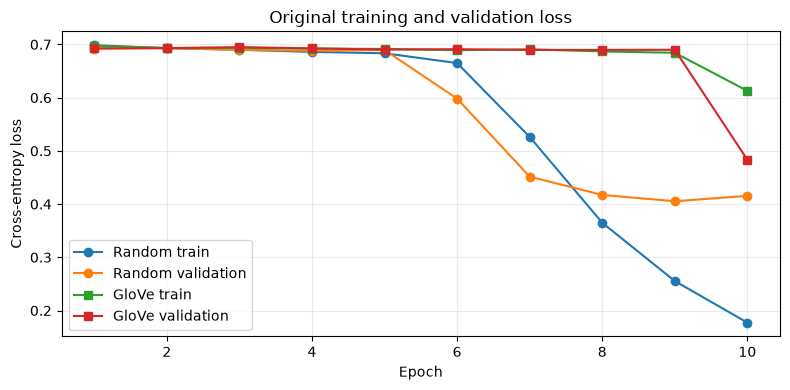

In [15]:
plt.figure(figsize=(8, 4))
epochs = range(1, len(random_train_losses) + 1)
plt.plot(epochs, random_train_losses, marker="o", label="Random train")
plt.plot(epochs, random_val_losses, marker="o", label="Random validation")
plt.plot(epochs, glove_train_losses, marker="s", label="GloVe train")
plt.plot(epochs, glove_val_losses, marker="s", label="GloVe validation")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Original training and validation loss")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "loss_curves.png", dpi=160, bbox_inches="tight")
plt.show()


## 8. 测试与比较

这里直接测试训练结束后的最后一轮模型，不加载验证集最佳 checkpoint。


Testing random embedding model:


Correct predictions: 2156
Total predictions: 2500
Accuracy: 0.8624
Precision: 0.8702
Recall: 0.8550
F1 Score: 0.8625
Confusion Matrix [[TN, FP], [FN, TP]]:
[[1077  161]
 [ 183 1079]]


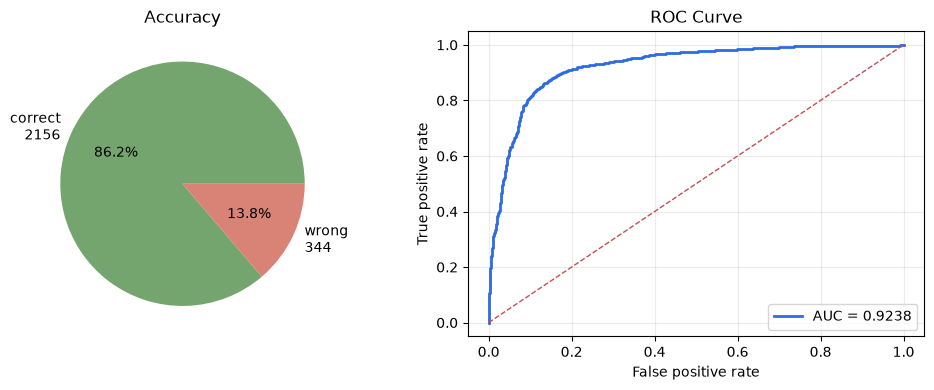

AUC: 0.9238

Testing frozen pretrained embedding model:


Correct predictions: 2048
Total predictions: 2500
Accuracy: 0.8192
Precision: 0.8115
Recall: 0.8360
F1 Score: 0.8236
Confusion Matrix [[TN, FP], [FN, TP]]:
[[ 993  245]
 [ 207 1055]]


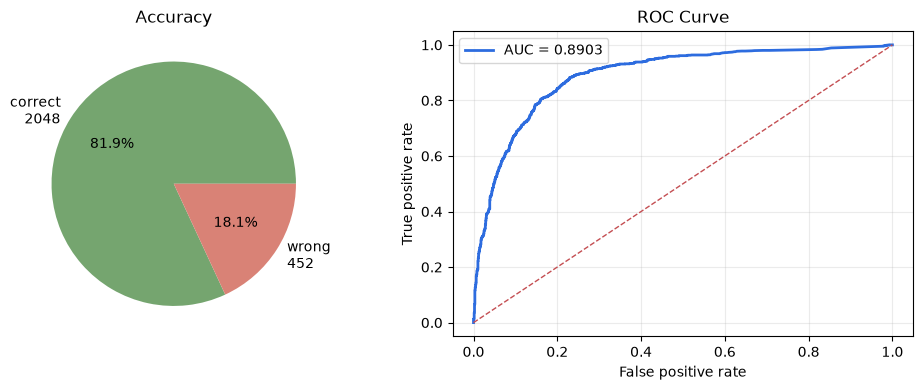

AUC: 0.8903

Model comparison:
Metric        Random    GloVe
--------------------------------
accuracy     0.8624    0.8192
precision    0.8702    0.8115
recall       0.8550    0.8360
f1           0.8625    0.8236
roc_auc      0.9238    0.8903


In [16]:
print("Testing random embedding model:")
random_metrics = test_model(model_random, test_loader)

print("\nTesting frozen pretrained embedding model:")
glove_metrics = test_model(model_pretrained_frozen, test_loader)

print("\nModel comparison:")
print("Metric        Random    GloVe")
print("--------------------------------")
for metric in ("accuracy", "precision", "recall", "f1", "roc_auc"):
    print(
        f"{metric:<12} "
        f"{random_metrics[metric]:.4f}    "
        f"{glove_metrics[metric]:.4f}"
    )


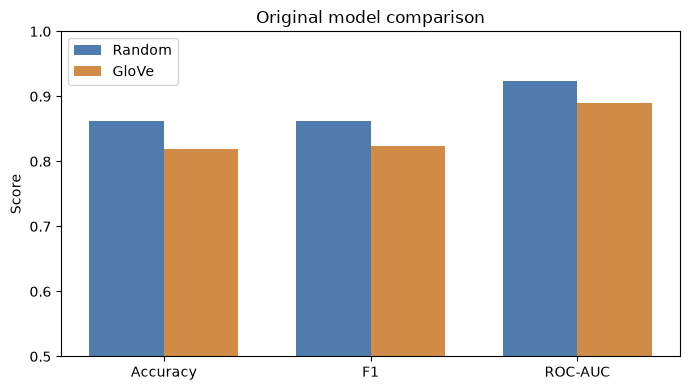

This run tests the last epoch, not a validation-selected checkpoint.
Random is higher on Accuracy and ROC-AUC in this run.


In [17]:
metrics_to_plot = ["accuracy", "f1", "roc_auc"]
x = np.arange(len(metrics_to_plot))
width = 0.36

plt.figure(figsize=(7, 4))
plt.bar(
    x - width / 2,
    [random_metrics[name] for name in metrics_to_plot],
    width,
    label="Random",
    color="#4f7cac",
)
plt.bar(
    x + width / 2,
    [glove_metrics[name] for name in metrics_to_plot],
    width,
    label="GloVe",
    color="#d18b47",
)
plt.xticks(x, ["Accuracy", "F1", "ROC-AUC"])
plt.ylim(0.5, 1.0)
plt.ylabel("Score")
plt.title("Original model comparison")
plt.legend()
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "metrics_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

summary = {
    "run_name": "original_minimal_execution_fix",
    "seed": SEED,
    "epochs": 10,
    "selection": "last epoch",
    "padding": "padding enters LSTM",
    "random_embedding_trainable": True,
    "glove_embedding_frozen": True,
    "random": random_metrics,
    "glove": glove_metrics,
    "history": {
        "random_train_loss": random_train_losses,
        "random_val_loss": random_val_losses,
        "glove_train_loss": glove_train_losses,
        "glove_val_loss": glove_val_losses,
    },
}
(ARTIFACT_DIR / "metrics.json").write_text(
    json.dumps(summary, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

print("This run tests the last epoch, not a validation-selected checkpoint.")
print(
    "Random is higher on Accuracy and ROC-AUC in this run."
    if random_metrics["accuracy"] > glove_metrics["accuracy"]
    and random_metrics["roc_auc"] > glove_metrics["roc_auc"]
    else "This single original run does not reproduce the historical ranking."
)


## 9. 如何解释这次运行

这次运行只能说明“当前代码在当前环境下产生了这些数值”。它不能证明随机
Embedding 本身比 GloVe 更好，因为两组实验至少同时改变了：

1. Embedding 初始化来源；
2. Embedding 是否可训练；
3. padding 是否进入 LSTM 的有效时间步；
4. 测试时是否选择了最佳验证轮次。

改进版会保持数据划分、词表和模型主体不变，只针对这些实验设计问题做小幅修改。
